# Alistamiento de capas geográficas
Equipo UBiK2 · Data Jam CVP 2026

**Objetivo:** preparar la capa de grupos de UPZ, las capas de presencia de la CVP y la capa de riesgo del POT.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q duckdb geopandas

import duckdb, geopandas as gpd, pandas as pd
print("DuckDB", duckdb.__version__, "| GeoPandas", gpd.__version__)

BASE = "/content/drive/MyDrive/UBiK2_DataJam"
import os
print(os.listdir(BASE))

DuckDB 1.3.2 | GeoPandas 1.2.0
['02_capas_geograficas.ipynb', 'datos_crudos', 'datos_procesados']


## 1. Capa de UPZ

In [6]:
CRUDOS = f"{BASE}/datos_crudos"
PROC   = f"{BASE}/datos_procesados"

upz = gpd.read_file(f"{CRUDOS}/ept_upz.zip")
print("UPZ:", len(upz), "| Sistema de coordenadas:", upz.crs)
upz[["CODIGO_UPZ", "NOMBRE"]].head()

UPZ: 112 | Sistema de coordenadas: PROJCS["PCS_CarMAGBOG",GEOGCS["GCS_CarMAGBOG",DATUM["CGS_CarMAGBOG",SPHEROID["GRS80 Mod",6380687,298.257222101]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",4.680486111],PARAMETER["central_meridian",-74.14659167],PARAMETER["scale_factor",1],PARAMETER["false_easting",92334.879],PARAMETER["false_northing",109320.965],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]


,CODIGO_UPZ,NOMBRE
0,16,SANTA BARBARA
1,31,SANTA CECILIA
2,19,EL PRADO
3,32,SAN BLAS
4,33,SOSIEGO


In [3]:
from datetime import date

fuentes = []

def registrar_fuente(nombre, entidad, url, archivo, notas=""):
    """Agrega una fuente al registro de procedencia de los datos."""
    fuentes.append({
        "conjunto_de_datos": nombre,
        "entidad": entidad,
        "url": url,
        "archivo": archivo,
        "fecha_descarga": date.today().isoformat(),
        "notas": notas,
    })

In [23]:
registrar_fuente(
    nombre="Espacio Público Total por UPZ 2021",
    entidad="DADEP",
    url="https://datosabiertos.bogota.gov.co/dataset/espacio-publico-total-upz-2021",
    archivo="ept_upz.zip",
    notas="Geometría de las 112 UPZ; base de las unidades de análisis",
)

### Reproyección capa UPZ a MAGNA-SIRGAS 2018 / Origen-Nacional (EPSG:9377)

In [9]:
upz_9377 = upz.to_crs(epsg=9377)

# Control de calidad: comparar el área original con la recalculada
upz_9377["area_ha_9377"] = upz_9377.geometry.area / 10_000
dif = (upz_9377["area_ha_9377"] - upz_9377["AREA_HECTA"]) / upz_9377["AREA_HECTA"] * 100

print("CRS nuevo:", upz_9377.crs.name)
print("Límites (x min, y min, x max, y max):", upz_9377.total_bounds.round(0))
print(f"Diferencia de área: promedio {dif.mean():.3f} %, máxima {dif.abs().max():.3f} %")

CRS nuevo: MAGNA-SIRGAS 2018 / Origen-Nacional
Límites (x min, y min, x max, y max): [4864331. 2050685. 4888045. 2091870.]
Diferencia de área: promedio -0.204 %, máxima 0.338 %


Control de calidad: al reproyectar de MAGNA-SIRGAS Cartesiana Bogotá a EPSG:9377 las áreas
difieren en promedio −0,20 % (máx. 0,34 %), por la diferencia de altura de referencia y el
factor de escala entre ambos sistemas. Es un efecto sistemático que no afecta los indicadores,
porque se expresan como proporciones.

### Asignación de las UPZ a los dominios de la Encuesta Multipropósito 2021

La Encuesta Multipropósito 2021 publica sus resultados para 95 dominios geográficos en Bogotá urbana,
y no para las 112 UPZ. En 80 casos el dominio coincide con una sola UPZ; en los 15 restantes la encuesta
agrupa dos o tres UPZ en un solo dominio (códigos 802 a 817), en general porque son zonas con pocos hogares.
Por ejemplo, el dominio 811 reúne las UPZ 59 (Alfonso López) y 61 (Ciudad Usme).

Para que la capa geográfica y la encuesta usen la misma unidad de análisis, a cada UPZ se le asigna el
código del dominio al que pertenece (campo cod_upz_grupo):
- Las 80 UPZ que la encuesta publica de forma individual conservan su propio código.
- Las 32 UPZ que forman parte de una agrupación reciben el código del grupo (802–817).

En el paso siguiente se unen (dissolve) los polígonos que comparten código, para obtener 95 unidades
de análisis, una por cada dominio de la encuesta.

Verificación: 80 UPZ individuales + 32 UPZ agrupadas = 112 UPZ de la capa del DADEP.

In [10]:
grupos_em = {
    802: [46, 113], 803: [15, 16], 804: [1, 10], 806: [2, 3, 17],
    807: [103, 22], 808: [104, 106], 809: [108, 111], 810: [31, 105],
    811: [59, 61], 812: [60, 56], 813: [117, 115], 814: [93, 91],
    815: [64, 68, 63], 816: [90, 99], 817: [97, 88],
}
upz_a_grupo = {u: g for g, lista in grupos_em.items() for u in lista}

upz_9377["CODIGO_UPZ"] = upz_9377["CODIGO_UPZ"].astype(int)
upz_9377["cod_upz_grupo"] = (upz_9377["CODIGO_UPZ"].map(upz_a_grupo)
                             .fillna(upz_9377["CODIGO_UPZ"]).astype(int))

print(upz_9377[upz_9377["cod_upz_grupo"] >= 800]
      .sort_values("cod_upz_grupo")[["cod_upz_grupo", "CODIGO_UPZ", "NOMBRE"]]
      .to_string(index=False))
print("Grupos resultantes:", upz_9377["cod_upz_grupo"].nunique())

 cod_upz_grupo  CODIGO_UPZ                     NOMBRE
           802         113                    BAVARIA
           802          46                   CASTILLA
           803          15               COUNTRY CLUB
           803          16              SANTA BARBARA
           804          10                   LA URIBE
           804           1  PASEO DE LOS LIBERTADORES
           806          17        SAN JOSE DE BAVARIA
           806           2                LA ACADEMIA
           806           3                  GUAYMARAL
           807         103             PARQUE SALITRE
           807          22            DOCE DE OCTUBRE
           808         106               LA ESMERALDA
           808         104 PARQUE SIMON BOLIVAR - CAN
           809         108            ZONA INDUSTRIAL
           809         111              PUENTE ARANDA
           810          31              SANTA CECILIA
           810         105            JARDIN BOTANICO
           811          61  

### Unidades de análisis: 112 UPZ y 95 dominios de la encuesta

Se unen (dissolve) las UPZ que comparten código de dominio. El dominio 804 (Paseo de los Libertadores +
La Uribe) queda como multipolígono porque sus dos UPZ no son contiguas; se conserva así porque la
encuesta los publica como un solo dominio estadístico. Los dominios 811, 812 y 815 presentaban
pequeñas aberturas de digitalización en sus límites compartidos, que se cierran con un buffer
de +0,5 m / −0,5 m sin modificar los límites exteriores.
Se generan dos capas: upz_112 (referencia y cruces espaciales) y upz_grupos_95 (unidad de análisis).

In [11]:
# 1. Unir las UPZ por dominio, conservando nombres y códigos de las UPZ que lo forman
grupos95 = upz_9377.dissolve(
    by="cod_upz_grupo",
    aggfunc={"NOMBRE": lambda s: " + ".join(sorted(s)),
             "CODIGO_UPZ": lambda s: ",".join(str(c) for c in sorted(s))}
).reset_index()
grupos95 = grupos95.rename(columns={"NOMBRE": "upz_incluidas", "CODIGO_UPZ": "codigos_upz"})

# 2. Cerrar rendijas de digitalización
grupos95["geometry"] = grupos95.geometry.buffer(0.5).buffer(-0.5)
grupos95["n_partes"] = grupos95.geometry.apply(lambda g: len(getattr(g, "geoms", [g])))
print("Dominios en varias partes:", grupos95.loc[grupos95.n_partes > 1, "cod_upz_grupo"].tolist())

# 3. Área en hectáreas
grupos95["area_ha"] = grupos95.geometry.area / 10_000

# 4. Unir la tabla de hogares de la encuesta
em = pd.read_csv(f"{CRUDOS}/upz_grupos_em2021.csv")
grupos95 = grupos95.merge(em, left_on="cod_upz_grupo", right_on="COD_UPZ_GRUPO",
                          how="left", indicator=True)
print(grupos95["_merge"].value_counts())
grupos95 = grupos95.drop(columns=["_merge", "COD_UPZ_GRUPO"])

print("Total de dominios:", len(grupos95))
grupos95[["cod_upz_grupo", "NOMBRE_UPZ_GRUPO", "upz_incluidas", "hogares_muestra", "area_ha"]].head()

Dominios en varias partes: [52, 804, 811, 812, 815]
_merge
both          95
left_only      0
right_only     0
Name: count, dtype: int64
Total de dominios: 95


,cod_upz_grupo,NOMBRE_UPZ_GRUPO,upz_incluidas,hogares_muestra,area_ha
0,9,Verbenal,VERBENAL,909,354.586864
1,11,San Cristóbal Norte,SAN CRISTOBAL NORTE,923,274.704034
2,12,Toberín,TOBERIN,930,290.060792
3,13,Los Cedros,LOS CEDROS,1088,670.868560
4,14,Usaquén,USAQUEN,1039,491.668293


Dominio 52: 2 partes · áreas (ha): [179.95, 7.38]
Dominio 804: 2 partes · áreas (ha): [629.64, 344.55]
Dominio 811: 2 partes · áreas (ha): [1124.2, 11.39]
Dominio 812: 2 partes · áreas (ha): [669.4, 36.94]
Dominio 815: 4 partes · áreas (ha): [1191.4, 23.71, 4.45, 1.26]


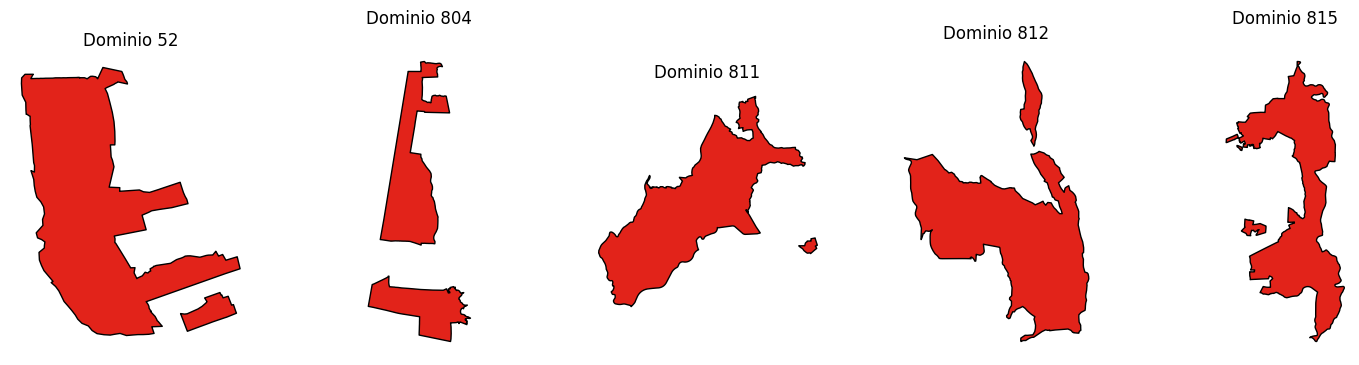

In [12]:
import matplotlib.pyplot as plt

revisar = [52, 804, 811, 812, 815]
for g in revisar:
    geom = grupos95.loc[grupos95.cod_upz_grupo == g, "geometry"].iloc[0]
    areas = sorted([p.area / 10_000 for p in geom.geoms], reverse=True)
    print(f"Dominio {g}: {len(areas)} partes · áreas (ha): {[round(a, 2) for a in areas]}")

fig, axes = plt.subplots(1, len(revisar), figsize=(18, 4))
for ax, g in zip(axes, revisar):
    grupos95[grupos95.cod_upz_grupo == g].plot(ax=ax, color="#E2231A", edgecolor="black")
    ax.set_title(f"Dominio {g}")
    ax.axis("off")
plt.show()

**Resultado del control de calidad.** Cinco dominios quedan como multipolígonos:
- 804 (Paseo de los Libertadores + La Uribe): sus dos UPZ no son contiguas.
- 52 (La Flora), 811 (Alfonso López + Ciudad Usme), 812 (Parque Entrenubes + Danubio)
  y 815 (Monteblanco + El Tesoro + El Mochuelo): incluyen UPZ que en la capa oficial del DADEP
  están conformadas por varios polígonos separados.
Todas las partes tienen un área igual o mayor a 1,26 ha y forma definida, por lo que corresponden
a sectores reales de cada UPZ y no a errores de digitalización. Se conservan sin modificaciones.

In [13]:
GPKG = f"{PROC}/ubik2.gpkg"
upz_9377.to_file(GPKG, layer="upz_112", driver="GPKG")
grupos95.to_file(GPKG, layer="upz_grupos_95", driver="GPKG")
print("Guardado en", GPKG)

Guardado en /content/drive/MyDrive/UBiK2_DataJam/datos_procesados/ubik2.gpkg


### Exportación de capas para el visor web

El archivo ubik2.gpkg es la base de trabajo del análisis: guarda las capas en MAGNA-SIRGAS 2018 /
Origen-Nacional (EPSG:9377) con la geometría completa, para que las áreas y los cruces espaciales
sean precisos. A partir de él se generan copias livianas en GeoJSON, una por capa, que son el
insumo del visor web.

La función exportar_web aplica tres ajustes a cada capa:
- Simplifica las geometrías con una tolerancia de 3 m, eliminando vértices que no se perciben
  a la escala del mapa.
- Reproyecta a WGS84 (EPSG:4326), el sistema que usan las librerías de mapas web.
- Limita las coordenadas a 6 decimales (precisión aproximada de 10 cm).

Los archivos se guardan en datos_procesados/web. Estas copias son solo para visualización:
todos los cálculos se hacen sobre el GeoPackage.

In [14]:
import os
WEB = f"{PROC}/web"
os.makedirs(WEB, exist_ok=True)

def exportar_web(gdf, nombre, tolerancia_m=3):
    """Simplifica en metros, pasa a WGS84 y guarda un GeoJSON liviano para el front."""
    capa = gdf.copy()
    capa["geometry"] = capa.geometry.simplify(tolerancia_m, preserve_topology=True)
    capa = capa.to_crs(epsg=4326)
    ruta = f"{WEB}/{nombre}.geojson"
    capa.to_file(ruta, driver="GeoJSON", COORDINATE_PRECISION=6)
    print(f"{nombre}.geojson · {len(capa)} elementos · {os.path.getsize(ruta)/1024:.0f} KB")

exportar_web(grupos95, "upz_grupos_95")
exportar_web(upz_9377[["CODIGO_UPZ", "NOMBRE", "cod_upz_grupo", "geometry"]], "upz_112")

upz_grupos_95.geojson · 95 elementos · 290 KB
upz_112.geojson · 112 elementos · 286 KB


## 2. Capas misionales de la CVP

Las cinco capas se descargan directamente de los servicios ArcGIS REST que la CVP publica
como datos abiertos (carpeta IDECA2024), para que el análisis parta siempre de la fuente
oficial y sea reproducible. Los servicios entregan un número máximo de registros por consulta,
por lo que la descarga se hace por páginas hasta completar la capa.

In [15]:
import requests

def descargar_capa_rest(url_capa):
    """Descarga todos los registros de una capa ArcGIS REST y la devuelve en EPSG:9377."""
    consulta = f"{url_capa}/query"
    total = requests.get(consulta, params={"where": "1=1", "returnCountOnly": "true", "f": "json"}).json()["count"]
    lote = requests.get(url_capa, params={"f": "json"}).json().get("maxRecordCount", 1000)
    partes = []
    for inicio in range(0, total, lote):
        r = requests.get(consulta, params={
            "where": "1=1", "outFields": "*", "outSR": 4326, "f": "geojson",
            "resultOffset": inicio, "resultRecordCount": lote,
        })
        partes.append(gpd.read_file(r.text))
    capa = pd.concat(partes, ignore_index=True).set_crs(4326, allow_override=True).to_crs(9377)
    print(f"Registros esperados: {total} · descargados: {len(capa)}")
    return capa

###Capa Geográfica Mejoramiento de Vivienda

In [16]:
URL_VIVIENDA = "https://geo.cvp.gov.co/arcgis/rest/services/IDECA2024/Mejoramiento_de_Vivienda/MapServer/0"
vivienda = descargar_capa_rest(URL_VIVIENDA)
print(list(vivienda.columns))
vivienda.head()

Registros esperados: 875 · descargados: 875
['OBJECTID', 'SHAPE_Length', 'SHAPE_Area', 'MViMAsi', 'MViMSdv', 'MViMLCo', 'MViIMV', 'MViProj', 'MViEATe', 'MViFEAs', 'MViLote', 'MViCHIP', 'geometry']


,OBJECTID,SHAPE_Length,SHAPE_Area,MViMAsi,MViMSdv,MViMLCo,MViIMV,MViProj,MViEATe,MViFEAs,MViLote,MViCHIP,geometry
0,765,0.000289,5.210599e-09,5,4,4,MV_PT_0001,7828-PLAN TERRAZAS,3,1664150400000,001355032002,AAA0005LTAW,"POLYGON ((4878299.014 2061202.715, 4878301.96 ..."
1,766,0.000258,3.894006e-09,5,4,4,MV_PT_0002,7828-PLAN TERRAZAS,3,1664582400000,001353025008,AAA0005PEWF,"POLYGON ((4877951.73 2061513.113, 4877946.562 ..."
2,767,0.000271,4.399504e-09,5,4,4,MV_PT_0003,7828-PLAN TERRAZAS,3,1668643200000,001353022010,AAA0005PDOM,"POLYGON ((4877934.875 2061503.647, 4877931.822..."
3,768,0.000334,6.391607e-09,5,4,4,MV_PT_0004,7828-PLAN TERRAZAS,3,1665619200000,001353028016,AAA0005RPXS,"POLYGON ((4877969.815 2061599.845, 4877970.504..."
4,769,0.000270,4.361051e-09,5,4,4,MV_PT_0005,7828-PLAN TERRAZAS,3,1667433600000,001353036015,AAA0005NBEP,"POLYGON ((4877959.326 2061615.198, 4877956.764..."


Traducir alias, dominios y fechas

In [17]:
import unicodedata, re

def limpiar_nombre(texto):
    """'Estado Asistencia Técnica' -> 'estado_asistencia_tecnica'"""
    t = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", t.lower()).strip("_")

def traducir_capa(url_capa, capa):
    """Reemplaza códigos de dominio por su descripción, convierte fechas y renombra con los alias."""
    meta = requests.get(url_capa, params={"f": "json"}).json()
    renombrar = {}
    for campo in meta["fields"]:
        nombre = campo["name"]
        if nombre not in capa.columns:
            continue
        dominio = campo.get("domain") or {}
        if dominio.get("type") == "codedValue":
            codigos = {str(cv["code"]): cv["name"] for cv in dominio["codedValues"]}
            capa[nombre] = capa[nombre].astype(str).map(codigos).fillna(capa[nombre].astype(str))
        if campo["type"] == "esriFieldTypeDate":
            capa[nombre] = pd.to_datetime(capa[nombre], unit="ms", errors="coerce")
        renombrar[nombre] = limpiar_nombre(campo.get("alias") or nombre)
    return capa.rename(columns=renombrar)

vivienda = traducir_capa(URL_VIVIENDA, vivienda)
print(list(vivienda.columns))
vivienda.drop(columns="geometry").head()

['objectid', 'shape_length', 'shape_area', 'modalidad_asistencia', 'modalidad_sdve', 'modalidad_licencia_construccion', 'identificador_mv', 'proyecto', 'estado_asistencia_tecnica', 'fecha_estado_asistencia', 'lotcodigo', 'chip', 'geometry']


,objectid,shape_length,shape_area,modalidad_asistencia,modalidad_sdve,modalidad_licencia_construccion,identificador_mv,proyecto,estado_asistencia_tecnica,fecha_estado_asistencia,lotcodigo,chip
0,765,0.000289,5.210599e-09,Reconocimiento y Licenciamiento,Vivienda Progresiva,Ampliación,MV_PT_0001,7828-PLAN TERRAZAS,Ejecutado,2022-09-26,001355032002,AAA0005LTAW
1,766,0.000258,3.894006e-09,Reconocimiento y Licenciamiento,Vivienda Progresiva,Ampliación,MV_PT_0002,7828-PLAN TERRAZAS,Ejecutado,2022-10-01,001353025008,AAA0005PEWF
2,767,0.000271,4.399504e-09,Reconocimiento y Licenciamiento,Vivienda Progresiva,Ampliación,MV_PT_0003,7828-PLAN TERRAZAS,Ejecutado,2022-11-17,001353022010,AAA0005PDOM
3,768,0.000334,6.391607e-09,Reconocimiento y Licenciamiento,Vivienda Progresiva,Ampliación,MV_PT_0004,7828-PLAN TERRAZAS,Ejecutado,2022-10-13,001353028016,AAA0005RPXS
4,769,0.000270,4.361051e-09,Reconocimiento y Licenciamiento,Vivienda Progresiva,Ampliación,MV_PT_0005,7828-PLAN TERRAZAS,Ejecutado,2022-11-03,001353036015,AAA0005NBEP


In [18]:
print(vivienda["estado_asistencia_tecnica"].value_counts(dropna=False), "\n")
print(vivienda["proyecto"].value_counts(dropna=False), "\n")
print("Fechas: desde", vivienda["fecha_estado_asistencia"].min(),
      "hasta", vivienda["fecha_estado_asistencia"].max())
print(vivienda.groupby(vivienda["fecha_estado_asistencia"].dt.year)["estado_asistencia_tecnica"]
      .value_counts().unstack(fill_value=0))

estado_asistencia_tecnica
Programado      466
Ejecutado       235
En Ejecución    174
Name: count, dtype: int64 

proyecto
7828-PLAN TERRAZAS    875
Name: count, dtype: int64 

Fechas: desde 2021-12-16 00:00:00 hasta 2024-11-20 00:00:00
estado_asistencia_tecnica  Ejecutado  En Ejecución  Programado
fecha_estado_asistencia                                       
2021                               1             0           0
2022                              58             0           0
2023                              69           174           0
2024                             107             0         466


#### Mejoramiento de Vivienda
La capa abierta contiene 875 predios, todos del proyecto 7828 Plan Terrazas, con fechas entre
diciembre de 2021 y noviembre de 2024. Por lo tanto, la presencia de esta línea corresponde a
Plan Terrazas y no al total de intervenciones de mejoramiento de vivienda de la CVP.
Se considera presencia la suma de los estados Ejecutado y En Ejecución (409 predios); los predios
Programados (466) se cuentan aparte como intervención prevista.

In [19]:
upz_ref = upz_9377[["CODIGO_UPZ", "cod_upz_grupo", "geometry"]]

def asignar_dominio(capa):
    """Agrega a cada registro el código de UPZ y de dominio según su punto interior."""
    puntos = capa.copy()
    puntos["geometry"] = capa.geometry.representative_point()
    unido = gpd.sjoin(puntos, upz_ref, how="left", predicate="within")
    capa = capa.copy()
    capa["CODIGO_UPZ"] = unido["CODIGO_UPZ"].values
    capa["cod_upz_grupo"] = unido["cod_upz_grupo"].values
    fuera = capa["cod_upz_grupo"].isna().sum()
    print(f"Registros: {len(capa)} · dentro de alguna UPZ: {len(capa) - fuera} · fuera: {fuera}")
    return capa

vivienda = asignar_dominio(vivienda)

Registros: 875 · dentro de alguna UPZ: 864 · fuera: 11


In [20]:
vivienda["es_presencia"] = vivienda["estado_asistencia_tecnica"].isin(["Ejecutado", "En Ejecución"])

conteo_viv = vivienda.groupby("cod_upz_grupo").agg(
    viv_presencia=("es_presencia", "sum"),
    viv_programado=("estado_asistencia_tecnica", lambda s: (s == "Programado").sum()),
).reset_index()
conteo_viv["cod_upz_grupo"] = conteo_viv["cod_upz_grupo"].astype(int)

print("Dominios con presencia de Mejoramiento de Vivienda:", (conteo_viv.viv_presencia > 0).sum())
conteo_viv.sort_values("viv_presencia", ascending=False).head(10)

Dominios con presencia de Mejoramiento de Vivienda: 12


,cod_upz_grupo,viv_presencia,viv_programado
15,811,145,116
1,50,71,0
10,67,57,60
12,70,38,13
3,52,19,40
11,69,15,39
2,51,14,18
8,58,12,49
6,55,12,18
7,57,9,60


In [21]:
vivienda.to_file(GPKG, layer="cvp_mejoramiento_vivienda", driver="GPKG")
registrar_fuente(
    nombre="Mejoramiento de Vivienda (Plan Terrazas)",
    entidad="Caja de la Vivienda Popular",
    url=URL_VIVIENDA,
    archivo="Servicio ArcGIS REST",
    notas="875 predios del proyecto 7828 Plan Terrazas, 2021-2024",
)

In [22]:
## Guardar el registro de fuentes
registro = pd.DataFrame(fuentes).drop_duplicates(subset="conjunto_de_datos", keep="last")
registro.to_csv(f"{PROC}/fuentes.csv", index=False, encoding="utf-8-sig")
print(f"Guardado en {PROC}/fuentes.csv · {len(registro)} fuentes")
registro

Guardado en /content/drive/MyDrive/UBiK2_DataJam/datos_procesados/fuentes.csv · 1 fuentes


,conjunto_de_datos,entidad,url,archivo,fecha_descarga,notas
0,Mejoramiento de Vivienda (Plan Terrazas),Caja de la Vivienda Popular,https://geo.cvp.gov.co/arcgis/rest/services/ID...,Servicio ArcGIS REST,2026-10-10,"875 predios del proyecto 7828 Plan Terrazas, 2..."


### Capa geográfica Vivienda Trámite Curaduría Pública Social

In [23]:
URL_CPS = "https://geo.cvp.gov.co/arcgis/rest/services/IDECA2024/Curaduria_Publica_Social/MapServer/0"
cps = descargar_capa_rest(URL_CPS)
cps = traducir_capa(URL_CPS, cps)
print(list(cps.columns))
cps.drop(columns="geometry").head()

Registros esperados: 1201 · descargados: 1201
['objectid_1', 'objectid', 'lotcodigo', 'chip', 'direccion', 'estrato', 'area_del', 'area_tot', 'acto_admo', 'fecha_de', 'fecha_de_1', 'clase_de', 'shape_length', 'shape_area', 'geometry']


,objectid_1,objectid,lotcodigo,chip,direccion,estrato,area_del,area_tot,acto_admo,fecha_de,fecha_de_1,clase_de,shape_length,shape_area
0,1,1,004597057017,AAA0150OSHY,KR 78A BIS 76A 22 SUR,Estrato 2,76.12,135.09,0133-21,2021-09-29,2021-10-11,CPS,0.000325,5.863308e-09
1,2,2,002529084014,AAA0024TRZM,KR 14M 92C 35 SUR,Estrato 2,64.05,124.16,0023-21,2021-06-30,2021-07-22,CPS,0.000325,5.862305e-09
2,3,3,004621021018,AAA0148ZTAW,KR 81J 42B 27 SUR,Estrato 2,141.59,141.59,0002-21,2021-05-28,2021-07-09,AR,0.000325,5.863274e-09
3,4,4,006517018022,AAA0162AYUH,CL 1B 82 53,Estrato 2,173.91,173.91,0006-21,2021-05-28,2021-06-08,AR,0.000321,5.702900e-09
4,5,5,006517035034,AAA0161ZKOM,CL 1A 81 27,Estrato 2,145.58,145.58,0004-21,2021-05-28,2021-06-23,AR,0.000324,5.784213e-09


#### Curaduría Pública Social
Cada registro corresponde a un predio con acto de reconocimiento expedido por la Curaduría Pública
Social (Especificación Técnica del objeto, CVP, 2025). Los nombres de los campos del servicio están
abreviados; su significado se tomó del Catálogo de Objetos (GIG-05-FR-01 V2) y del Diccionario de
Datos (GIG-06-FR-02 V3), que describen los mismos 10 atributos en el mismo orden.
El campo de trámite trae los valores CPS y AR, que no aparecen en el dominio documentado
(pendiente de confirmar con la dirección). Ambos se cuentan como presencia.

In [24]:
cps = cps.rename(columns={
    "area_del": "area_reconocida_m2",
    "area_tot": "area_construida_m2",
    "acto_admo": "acto_administrativo",
    "fecha_de": "fecha_acto",
    "fecha_de_1": "fecha_ejecutoria",
    "clase_de": "tipo_tramite",
})

print(cps["tipo_tramite"].value_counts(dropna=False), "\n")
print(cps["estrato"].value_counts(dropna=False), "\n")
print("Fecha del acto: desde", cps["fecha_acto"].min(), "hasta", cps["fecha_acto"].max())
print(cps.groupby(cps["fecha_acto"].dt.year)["tipo_tramite"].value_counts().unstack(fill_value=0), "\n")
print("Predios únicos (CHIP):", cps["chip"].nunique(), "de", len(cps), "registros")

tipo_tramite
CPS    1190
AR       11
Name: count, dtype: int64 

estrato
Estrato 1    1016
Estrato 2     185
Name: count, dtype: int64 

Fecha del acto: desde 2021-05-28 00:00:00 hasta 2024-10-31 00:00:00
tipo_tramite  AR  CPS
fecha_acto           
2021.0        10  240
2022.0         0  495
2023.0         0  383
2024.0         1   54 

Predios únicos (CHIP): 1201 de 1201 registros


In [25]:
registrar_fuente(
    nombre="Trámite Curaduría Pública Social",
    entidad="Caja de la Vivienda Popular",
    url= "https://geo.cvp.gov.co/arcgis/rest/services/IDECA2024/Curaduria_Publica_Social/MapServer/0",
    archivo="Servicio ArcGIS REST",
    notas="Predios con acto de reconocimiento; significado de campos según Catálogo y Diccionario CVP",
)

In [26]:
print("Registros sin fecha del acto:", cps["fecha_acto"].isna().sum())

cps = asignar_dominio(cps)

conteo_cps = (cps.groupby("cod_upz_grupo").size()
              .rename("cps_presencia").reset_index())
conteo_cps["cod_upz_grupo"] = conteo_cps["cod_upz_grupo"].astype(int)

print("Dominios con presencia de la Curaduría Pública Social:", len(conteo_cps))
conteo_cps.sort_values("cps_presencia", ascending=False).head(10)

Registros sin fecha del acto: 18
Registros: 1201 · dentro de alguna UPZ: 1185 · fuera: 16
Dominios con presencia de la Curaduría Pública Social: 20


,cod_upz_grupo,cps_presencia
17,811,324
10,67,164
3,52,99
7,57,96
11,69,87
1,50,82
8,58,78
12,70,72
2,51,43
6,55,42


In [27]:
cps.to_file(GPKG, layer="cvp_curaduria_publica_social", driver="GPKG")

Resultado: 1.201 predios con acto de reconocimiento (mayo de 2021 a octubre de 2024), todos de
estratos 1 y 2, con un acto por predio. 18 registros no tienen fecha del acto y 16 quedan fuera
de las UPZ urbanas (1,3 %). La presencia se concentra en 20 dominios, que coinciden en su mayoría
con los de Plan Terrazas (Usme, Ciudad Bolívar, San Cristóbal).

###Capa Geográfica Titulación Predial

In [28]:
import requests

def descargar_capa_rest(url_capa):
    info = requests.get(url_capa, params={"f": "json"}).json()
    paginacion = info.get("advancedQueryCapabilities", {}).get("supportsPagination", False)
    lote_max = info.get("maxRecordCount", 1000)

    # 1. Lista de OBJECTID
    r = requests.get(f"{url_capa}/query",
                     params={"where": "1=1", "returnIdsOnly": "true", "f": "json"}).json()
    ids = sorted(r["objectIds"])
    print(f"Esperados: {len(ids)} | paginación nativa: {paginacion} | tamaño de lote: {lote_max}")

    # 2. Descarga por lotes de IDs (POST para no exceder el largo de la URL)
    partes = []
    for i in range(0, len(ids), lote_max):
        lote = ids[i:i + lote_max]
        resp = requests.post(f"{url_capa}/query", data={
            "objectIds": ",".join(map(str, lote)),
            "outFields": "*", "outSR": 4326, "f": "geojson"}).json()
        partes.append(gpd.GeoDataFrame.from_features(resp["features"], crs=4326))

    capa = pd.concat(partes, ignore_index=True).to_crs(epsg=9377)
    print(f"Descargados: {len(capa)}")
    return capa

In [29]:
URL_TITULACION = "https://geo.cvp.gov.co/arcgis/rest/services/IDECA2024/titulacion_Predial/MapServer/0"
titulacion = descargar_capa_rest(URL_TITULACION)
titulacion = traducir_capa(URL_TITULACION, titulacion)
print(list(titulacion.columns))
titulacion.drop(columns="geometry").head()

Esperados: 5903 | paginación nativa: False | tamaño de lote: 10000
Descargados: 5903
['geometry', 'fid', 'objectid', 'shape_leng', 'shape_area', 'codigo_plano', 'mecanismo_de_titulacion', 'titulo_entregado', 'numero_del_titulo', 'fecha_del_titulo']


,fid,objectid,shape_leng,shape_area,codigo_plano,mecanismo_de_titulacion,titulo_entregado,numero_del_titulo,fecha_del_titulo
0,0,8407,0.000322,5.730762e-09,006517044011000,CESIÓN A TITULO GRATUITO,RESOLUCIÓN,4368,2018-10-03
1,1,8408,0.000324,5.815244e-09,006517045017000,CESIÓN A TITULO GRATUITO,RESOLUCIÓN,3691,2018-09-26
2,2,8409,0.000323,5.840202e-09,006517047039000,CESIÓN A TITULO GRATUITO,RESOLUCIÓN,4271,2018-10-03
3,3,8410,0.000324,5.798892e-09,006517064025000,CESIÓN A TITULO GRATUITO,RESOLUCIÓN,4188,2018-10-03
4,4,8411,0.000326,5.925481e-09,006517045016000,CESIÓN A TITULO GRATUITO,RESOLUCIÓN,3539,2018-09-26


In [30]:
titulacion = titulacion.drop(columns=["fid", "shape_leng", "shape_area"])
titulacion["anio_titulo"] = titulacion["fecha_del_titulo"].dt.year

print(titulacion["mecanismo_de_titulacion"].value_counts(dropna=False), "\n")
print(titulacion["titulo_entregado"].value_counts(dropna=False), "\n")
print(titulacion["anio_titulo"].value_counts(dropna=False).sort_index(), "\n")
print("Códigos de plano repetidos:", titulacion["codigo_plano"].duplicated().sum())
print("Sin fecha:", titulacion["fecha_del_titulo"].isna().sum())

mecanismo_de_titulacion
CESIÓN A TITULO GRATUITO    4667
TRANSFERENCIA DE DOMINIO     399
SANEAMIENTO                  316
PERTENENCIA                  289
MEDIACIÓN                    232
Name: count, dtype: int64 

titulo_entregado
RESOLUCIÓN           5322
ESCRITURA PÚBLICA     292
SENTENCIA             289
Name: count, dtype: int64 

anio_titulo
2015.0       1
2016.0      10
2017.0      45
2018.0    2419
2019.0     305
2020.0     487
2021.0     869
2022.0     672
2023.0     501
2024.0     310
2025.0     277
NaN          7
Name: count, dtype: int64 

Códigos de plano repetidos: 7
Sin fecha: 7


#### Titulación Predial
La capa registra 5.903 títulos entre 2015 y 2025, con cinco mecanismos. Saneamiento (316 registros) no figura en el dominio documentado en el Catálogo de Objetos. Se toma todo el histórico como presencia acumulada, porque la titulación es un efecto permanente sobre el predio. La presencia por dominio se mide en predios únicos según codigo_plano, para no contar dos veces los lotes con más de un título.

In [31]:
rep = titulacion[titulacion["codigo_plano"].duplicated(keep=False)].sort_values("codigo_plano")
print(rep[["codigo_plano", "mecanismo_de_titulacion", "numero_del_titulo", "fecha_del_titulo"]])

titulacion = asignar_dominio(titulacion)

conteo_tit = (titulacion.dropna(subset=["cod_upz_grupo"])
              .groupby("cod_upz_grupo")["codigo_plano"].nunique()
              .rename("tit_presencia"))
print(f"Dominios con titulación: {len(conteo_tit)} | predios únicos: {conteo_tit.sum()}")
print(conteo_tit.sort_values(ascending=False).head(10))

         codigo_plano   mecanismo_de_titulacion  numero_del_titulo  \
2515  002412064001000  CESIÓN A TITULO GRATUITO               5669   
5533  002412064001000               SANEAMIENTO                708   
3285  002565003001000  CESIÓN A TITULO GRATUITO               1640   
4136  002565003001000  CESIÓN A TITULO GRATUITO               1640   
3054  002566068009000  CESIÓN A TITULO GRATUITO               4280   
3194  002566068009000  CESIÓN A TITULO GRATUITO               4280   
4160  002580014001000  CESIÓN A TITULO GRATUITO               2376   
4171  002580014001000  CESIÓN A TITULO GRATUITO               2376   
2563  003210011023000  CESIÓN A TITULO GRATUITO               5429   
2564  003210011023000  CESIÓN A TITULO GRATUITO               5429   
2565  003210011023000  CESIÓN A TITULO GRATUITO               5429   
2615  004619015018000                 MEDIACIÓN               2354   
2616  004619015018000                 MEDIACIÓN               2354   

     fecha_del_titu

In [32]:
titulacion["cod_upz_grupo"] = titulacion["cod_upz_grupo"].astype("Int64")
titulacion["CODIGO_UPZ"] = titulacion["CODIGO_UPZ"].astype("Int64")
titulacion.to_file(GPKG, layer="cvp_titulacion_predial", driver="GPKG")

registrar_fuente("Titulación Predial", "Caja de la Vivienda Popular", "https://geo.cvp.gov.co/arcgis/rest/services/IDECA2024/titulacion_Predial/MapServer/0",
                 "ubik2.gpkg / cvp_titulacion_predial",
                 "5.903 títulos 2015–2025; 6 duplicados y 7 sin fecha; Saneamiento fuera del dominio documentado")

De los 5.903 registros, 5.899 caen dentro de alguna UPZ y 4 quedan por fuera. La presencia por dominio se mide en predios únicos (5.893), lo que absorbe cinco duplicados exactos de cargue, un predio con dos actuaciones distintas (cesión y saneamiento) y un título registrado con dos fechas (Resolución 1640). La titulación tiene presencia en 32 dominios, y Lucero y Corabastos concentran el 61 % de los predios titulados.

### Capa geográfica Reasentamiento por alto riesgo no mitigable

In [33]:
URL_REAS = "https://geo.cvp.gov.co/arcgis/rest/services/IDECA2024/reasentamientos/MapServer/0"
reas = descargar_capa_rest(URL_REAS)
reas = traducir_capa(URL_REAS, reas)
print(list(reas.columns))
display(reas.drop(columns="geometry").head())

for col in reas.columns:
    if col != "geometry" and reas[col].dtype == object and reas[col].nunique() <= 15:
        print(f"\n{col}\n{reas[col].value_counts(dropna=False)}")

Esperados: 19520 | paginación nativa: True | tamaño de lote: 10000
Descargados: 19520
['geometry', 'objectid', 'id_reas', 'shape_length', 'shape_area', 'estado']


,objectid,id_reas,shape_length,shape_area,estado
0,1,1997-1-754,0.000442,1.044485e-08,Adquisición predial por IDIGER
1,2,2011-1-13128,0.000641,2.074641e-08,Reasentamiento terminado
2,3,2011-1-13130,0.000575,1.232493e-08,En proceso
3,4,2009-AP36-00021,0.000294,5.132418e-09,En proceso
4,5,2009-AP36-00022,0.000283,4.687050e-09,En proceso



estado
estado
Reasentamiento terminado                    10063
En proceso                                   5993
Adquisición predial por IDIGER               2314
Cierre Administrativo Sin Reasentamiento     1150
Name: count, dtype: int64


In [34]:
reas = reas.drop(columns=["shape_length", "shape_area"])
reas["anio_reas"] = pd.to_numeric(reas["id_reas"].str[:4], errors="coerce").astype("Int64")

print("Años no válidos:", reas["anio_reas"].isna().sum(),
      "| rango:", reas["anio_reas"].min(), "-", reas["anio_reas"].max())
print("id_reas repetidos:", reas["id_reas"].duplicated().sum(), "\n")
print(pd.crosstab(reas["anio_reas"], reas["estado"]).tail(15))

reas = asignar_dominio(reas)
reas_ok = reas.dropna(subset=["cod_upz_grupo"])

conteo_reas = pd.concat([
    reas_ok[reas_ok["estado"] == "Reasentamiento terminado"].groupby("cod_upz_grupo")["id_reas"].nunique().rename("reas_presencia"),
    reas_ok[reas_ok["estado"] == "En proceso"].groupby("cod_upz_grupo")["id_reas"].nunique().rename("reas_en_proceso")
], axis=1).fillna(0).astype(int)

print(f"\nDominios con reasentamiento terminado: {(conteo_reas['reas_presencia'] > 0).sum()}")
print(conteo_reas.sort_values("reas_presencia", ascending=False).head(10))

Años no válidos: 81 | rango: 1000 - 9473
id_reas repetidos: 6 

estado     Adquisición predial por IDIGER  \
anio_reas                                   
9453                                    0   
9455                                    0   
9456                                    0   
9457                                    0   
9458                                    0   
9459                                    0   
9462                                    0   
9463                                    0   
9464                                    0   
9465                                    0   
9466                                    0   
9469                                    0   
9470                                    0   
9471                                    0   
9473                                    0   

estado     Cierre Administrativo Sin Reasentamiento  En proceso  \
anio_reas                                                         
9453                                

#### Reasentamiento

La capa tiene 19.520 registros en cuatro estados. Como presencia de la CVP se cuentan solo los reasentamientos terminados. Los procesos en curso se llevan en una columna aparte, y se excluyen los cierres administrativos sin reasentamiento y las adquisiciones prediales de IDIGER, anteriores a 2002 y ajenas a la gestión de la entidad. El año del proceso se extrae de los primeros cuatro caracteres de id_reas. Los conteos se hacen sobre identificadores únicos.



Con año válido: 19392 | sin año válido: 47
               id_reas                                    estado
8984   9432-AP-19-2005                  Reasentamiento terminado
8980   9436-AP-19-2005                  Reasentamiento terminado
16698     9452-18-2005                                En proceso
16420     9471-18-2005                                En proceso
3872   9440-AP-19-2005                  Reasentamiento terminado
4168   9430-AP-19-2005                  Reasentamiento terminado
13161     9450-18-2005  Cierre Administrativo Sin Reasentamiento
15429     9086-19-2004                  Reasentamiento terminado
16946  9425-AP-19-2005                                En proceso
8986   9426-AP-19-2005                  Reasentamiento terminado
8974   9437-AP-19-2005                  Reasentamiento terminado
16695     9470-18-2005  Cierre Administrativo Sin Reasentamiento
16949  9443-AP-19-2005                  Reasentamiento terminado
15654     9091-19-2005  Cierre Administrativo S

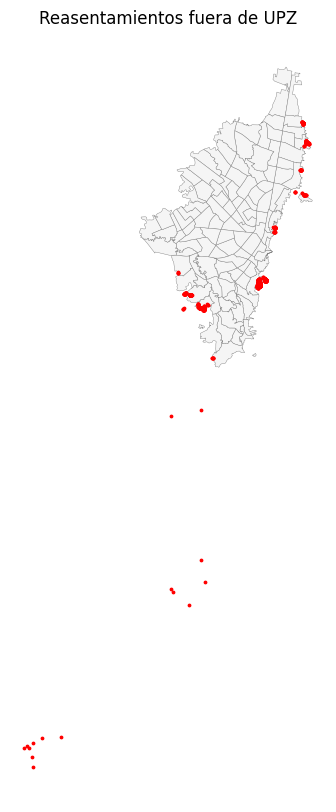

In [35]:
# Formatos del identificador cuando el año no es válido
anio_valido = reas["anio_reas"].between(1990, 2026)
print("Con año válido:", anio_valido.sum(), "| sin año válido:", (~anio_valido).sum())
print(reas.loc[~anio_valido, ["id_reas", "estado"]].sample(15, random_state=1))
print(reas.loc[~anio_valido, "estado"].value_counts())

reas.loc[~anio_valido, "anio_reas"] = pd.NA

# Registros fuera de UPZ sobre el mapa
fuera = reas[reas["cod_upz_grupo"].isna()]
print("\nFuera de UPZ por estado:\n", fuera["estado"].value_counts())
ax = upz_9377.plot(figsize=(8, 10), color="whitesmoke", edgecolor="grey", linewidth=0.3)
fuera.representative_point().plot(ax=ax, color="red", markersize=3)
ax.set_title("Reasentamientos fuera de UPZ"); ax.set_axis_off()

In [36]:
anio_ini = reas["id_reas"].str.extract(r"^((?:19|20)\d{2})")[0]
anio_fin = reas["id_reas"].str.extract(r"((?:19|20)\d{2})$")[0]
reas["anio_reas"] = pd.to_numeric(anio_ini.fillna(anio_fin), errors="coerce").astype("Int64")
reas.loc[~reas["anio_reas"].between(1990, 2026).fillna(False), "anio_reas"] = pd.NA

print("Sin año:", reas["anio_reas"].isna().sum())
print(reas.loc[reas["anio_reas"].isna(), "id_reas"].head(10).tolist())

Sin año: 81
['A.P. 20', 'A.P. 16', 'A.P. 24', 'A.P. 56', 'A.P. 73', 'A.P. 37', 'A.P. 52', 'A.P. 71', 'A.P. 54', 'A.P. 14']


In [37]:
print(reas.loc[reas["anio_reas"].isna(), "estado"].value_counts())

estado
Reasentamiento terminado                    80
Cierre Administrativo Sin Reasentamiento     1
Name: count, dtype: int64


Año y registros fuera de UPZ en Reasentamientos. El identificador id_reas no tiene un formato único: en la mayoría el año está al inicio (2011-1-13128) y en otros al final (9432-AP-19-2005). El año se extrae con una expresión regular que busca un valor entre 1990 y 2026 en cualquiera de las dos posiciones. Los 1.173 registros que quedan fuera de UPZ se ubican en los bordes oriental, suroriental y suroccidental de la ciudad, en suelo rural o de protección. Se conservan en la capa sin dominio asignado, porque la unidad de análisis (Encuesta Multipropósito 2021) cubre solo la cabecera urbana. De ellos, 655 son reasentamientos terminados.

In [38]:
reas["cod_upz_grupo"] = reas["cod_upz_grupo"].astype("Int64")
reas["CODIGO_UPZ"] = reas["CODIGO_UPZ"].astype("Int64")
reas.to_file(GPKG, layer="cvp_reasentamientos", driver="GPKG")

registrar_fuente("Reasentamientos", "Caja de la Vivienda Popular", URL_REAS,
                 "ubik2.gpkg / cvp_reasentamientos",
                 "19.520 registros; presencia = terminados; 1.173 fuera de UPZ (suelo rural/protección); "
                 "6 id_reas repetidos; formatos de identificador heterogéneos")

### Capa geográfica Mejoramiento de Barrios

In [39]:
URL_BARRIOS = "https://geo.cvp.gov.co/arcgis/rest/services/IDECA2024/mejoramientodebarrios/MapServer/0"
barrios = descargar_capa_rest(URL_BARRIOS)
barrios = traducir_capa(URL_BARRIOS, barrios)
print(list(barrios.columns))
print(barrios.geom_type.value_counts())
display(barrios.drop(columns="geometry").head())

for col in barrios.columns:
    if col != "geometry" and barrios[col].dtype == object and barrios[col].nunique() <= 20:
        print(f"\n{col}\n{barrios[col].value_counts(dropna=False)}")

Esperados: 557 | paginación nativa: True | tamaño de lote: 10000
Descargados: 557
['geometry', 'objectid', 'id_intervencion', 'nomenclatura', 'tipo_de_intervencion', 'codigo_localidad', 'barrio_legalizado', 'numero_de_contrato', 'ano_de_contrato', 'numero_contrato_interventoria', 'ano_contrato_interventoria', 'tipo_de_contrato', 'estado_de_contrato', 'entidad_contratante', 'enlace_contrato', 'id_elemento', 'tipo_de_elemento', 'funcion_de_elemento', 'area_de_elemento']
Polygon         555
MultiPolygon      2
Name: count, dtype: int64


,objectid,id_intervencion,nomenclatura,tipo_de_intervencion,codigo_localidad,barrio_legalizado,numero_de_contrato,ano_de_contrato,numero_contrato_interventoria,ano_contrato_interventoria,tipo_de_contrato,estado_de_contrato,entidad_contratante,enlace_contrato,id_elemento,tipo_de_elemento,funcion_de_elemento,area_de_elemento
0,1,19003945,KR 69 ENTRE CL 76 BIS A SUR Y CL 76A SUR,1,19,CARACOLI,720,2022,0,0,1,1,1,https://community.secop.gov.co/Public/Tenderin...,448439,2,4,66.763684
1,2,19003927,KR 70 ENTRE CL 76 BIS A SUR Y CL 76A SUR,1,19,CARACOLI,720,2022,0,0,1,1,1,https://community.secop.gov.co/Public/Tenderin...,92071163,2,4,50.516132
2,3,19003945,KR 69 ENTRE CL 76 BIS A SUR Y CL 76A SUR,1,19,CARACOLI,720,2022,0,0,1,1,1,https://community.secop.gov.co/Public/Tenderin...,448441,2,4,43.856508
3,4,19003960,KR 68 ENTRE CL 76 BIS A SUR Y CL 76A SUR,1,19,CARACOLI,720,2022,0,0,1,1,1,https://community.secop.gov.co/Public/Tenderin...,448475,2,4,57.026961
4,5,19003913,KR 71 ENTRE CL 76 BIS A SUR Y CL 76A SUR,1,19,CARACOLI,720,2022,0,0,1,1,1,https://community.secop.gov.co/Public/Tenderin...,92071162,2,4,49.980506



codigo_localidad
codigo_localidad
04    145
05    145
11    128
19     62
18     38
07     18
01     17
03      4
Name: count, dtype: int64

enlace_contrato
enlace_contrato
https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noticeUID=CO1.NTC.2222959&isFromPublicArea=True&isModal=False                                                                       147
https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noticeUID=CO1.NTC.1892050&isFromPublicArea=True&isModal=False                                                                       125
https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noticeUID=CO1.NTC.2093229&isFromPublicArea=True&isModal=False                                                                       118
https://community.secop.gov.co/Public/Tendering/OpportunityDetail/Index?noticeUID=CO1.NTC.2121907&isFromPublicArea=True&isModal=False                                                                     

El servicio publica los campos categóricos como códigos sin dominio asociado, por lo que se tradujeron manualmente con las listas 300030 a 300035 del Diccionario de Datos de la CVP (GIG-06-FR-02 V3). Los valores de id_intervencion corresponden a tramos viales (formato CIV) y no a obras completas. La obra se identifica por el número y el año del contrato.

In [40]:
dom_barrios = {
    "tipo_de_intervencion": {1: "Vía", 2: "Parque", 3: "Plazoleta", 4: "Puente peatonal",
                             5: "Salón comunal", 6: "Baranda", 7: "Muro de contención"},
    "tipo_de_contrato":     {1: "Construcción", 2: "Estudios y diseños", 3: "Rehabilitación", 4: "Actualización"},
    "estado_de_contrato":   {1: "En ejecución", 2: "Terminado"},
    "entidad_contratante":  {1: "Caja de la Vivienda Popular", 2: "Secretaría Distrital del Hábitat",
                             3: "Alcaldía local", 4: "No aplica"},
    "tipo_de_elemento":     {1: "Calzada", 2: "Andén", 3: "No aplica"},
    "funcion_de_elemento":  {1: "Vehicular", 2: "Peatonal", 3: "Vehicular restringido", 4: "No aplica"},
}
for campo, dominio in dom_barrios.items():
    barrios[campo] = pd.to_numeric(barrios[campo], errors="coerce").map(dominio).fillna("Sin dominio")
    print(f"\n{barrios[campo].value_counts(dropna=False)}")

print("\nIntervenciones únicas:", barrios["id_intervencion"].nunique(),
      "| contratos:", barrios[["numero_de_contrato", "ano_de_contrato"]].drop_duplicates().shape[0])
print(barrios.groupby(["ano_de_contrato", "numero_de_contrato", "estado_de_contrato", "entidad_contratante"])
             .agg(elementos=("id_elemento", "size"), intervenciones=("id_intervencion", "nunique"),
                  area_m2=("area_de_elemento", "sum")).round(0))


tipo_de_intervencion
Vía    557
Name: count, dtype: int64

tipo_de_contrato
Construcción    557
Name: count, dtype: int64

estado_de_contrato
En ejecución    382
Terminado       143
Sin dominio      32
Name: count, dtype: int64

entidad_contratante
Caja de la Vivienda Popular    557
Name: count, dtype: int64

tipo_de_elemento
Andén          366
Calzada        124
Sin dominio     34
No aplica       33
Name: count, dtype: int64

funcion_de_elemento
No aplica                368
Vehicular                 96
Peatonal                  45
Sin dominio               32
Vehicular restringido     16
Name: count, dtype: int64

Intervenciones únicas: 233 | contratos: 13
                                                                                   elementos  \
ano_de_contrato numero_de_contrato estado_de_contrato entidad_contratante                      
2020            1125               Terminado          Caja de la Vivienda Popular          3   
2021            416                En ejecuci

In [41]:
barrios = barrios[barrios["entidad_contratante"] == "Caja de la Vivienda Popular"]
barrios = asignar_dominio(barrios)
b_ok = barrios.dropna(subset=["cod_upz_grupo"])

conteo_barrios = b_ok.groupby("cod_upz_grupo").agg(
    barrios_presencia=("id_intervencion", "nunique"),
    barrios_area_m2=("area_de_elemento", "sum")).round(0)
print(f"Dominios con mejoramiento de barrios: {len(conteo_barrios)}")
print(conteo_barrios.sort_values("barrios_presencia", ascending=False).head(10))

barrios["cod_upz_grupo"] = barrios["cod_upz_grupo"].astype("Int64")
barrios["CODIGO_UPZ"] = barrios["CODIGO_UPZ"].astype("Int64")
barrios.to_file(GPKG, layer="cvp_mejoramiento_barrios", driver="GPKG")

registrar_fuente("Mejoramiento de Barrios", "Caja de la Vivienda Popular", URL_BARRIOS,
                 "ubik2.gpkg / cvp_mejoramiento_barrios",
                 "557 elementos, 233 tramos, 13 contratos 2020–2023; dominios sin publicar en el servicio; "
                 "estado de contrato desactualizado; contratos 628 y 633 de 2023 sin estado ni área")

Registros: 557 · dentro de alguna UPZ: 494 · fuera: 63
Dominios con mejoramiento de barrios: 19
               barrios_presencia  barrios_area_m2
cod_upz_grupo                                    
71.0                          54           6019.0
32.0                          25           7834.0
69.0                          22           9605.0
811.0                         20          10721.0
52.0                          16           5623.0
55.0                          12           3612.0
57.0                          12           4454.0
67.0                           8           1803.0
51.0                           7           2700.0
54.0                           5           1010.0


#### Mejoramiento de Barrios

Se descargó la capa desde el servicio IDECA2024/mejoramientodebarrios. A diferencia de las demás líneas, cada registro corresponde a un elemento de obra (vía, andén, escalera, muro, espacio público) y no a un predio, y una misma intervención puede tener varios elementos. Antes de asignar dominio se revisan el tipo de geometría y la distribución de los campos categóricos, en especial la entidad contratante y el estado del contrato.

Todos los registros corresponden a contratos de la CVP (13 contratos entre 2020 y 2023). No se filtra por estado, porque el campo parece desactualizado: siete contratos de 2021 y 2022 figuran "En ejecución". La presencia por dominio se mide en tramos viales únicos (id_intervencion), ya que un mismo tramo puede aparecer en más de un contrato. El área intervenida se suma como dato complementario. Los contratos 628 y 633 de 2023 no tienen estado, función de elemento ni área: cuentan como tramos intervenidos, pero no suman área.

codigo_localidad  barrio_legalizado               
04                LA CECILIA                          18
                  LOS LAURELES SUR ORIENTAL I SEC.    45
dtype: int64
count     63.0
mean      78.2
std       44.7
min        0.7
25%       44.4
50%       83.2
75%      111.4
max      167.6
dtype: float64


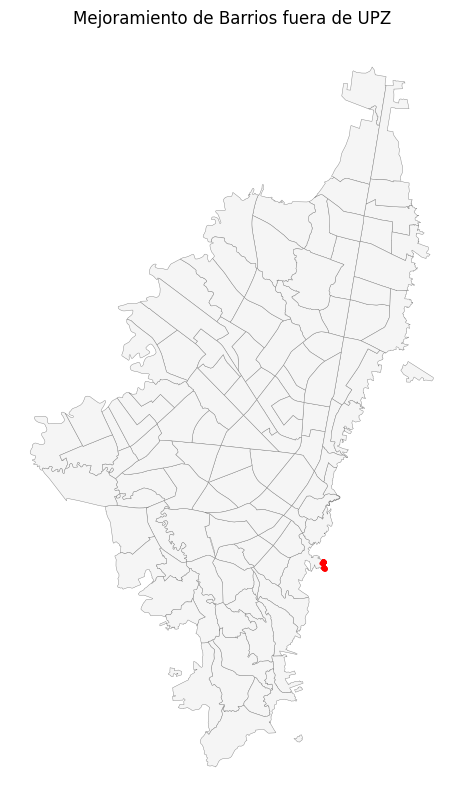

In [42]:
fuera_b = barrios[barrios["cod_upz_grupo"].isna()]
print(fuera_b.groupby(["codigo_localidad", "barrio_legalizado"]).size())

ax = upz_9377.plot(figsize=(8, 10), color="whitesmoke", edgecolor="grey", linewidth=0.3)
fuera_b.representative_point().plot(ax=ax, color="red", markersize=4)
ax.set_title("Mejoramiento de Barrios fuera de UPZ"); ax.set_axis_off()

# Distancia a la UPZ más cercana: si son pocos metros, es un hueco entre límites
dist = fuera_b.representative_point().apply(lambda p: upz_9377.distance(p).min())
print(dist.describe().round(1))

In [43]:
sin_dom = barrios["cod_upz_grupo"].isna()
pts = barrios.loc[sin_dom].copy()
pts["geometry"] = pts.geometry.representative_point()
cerca = gpd.sjoin_nearest(pts[["geometry"]], upz_ref, how="left", max_distance=200, distance_col="dist_m")
cerca = cerca[~cerca.index.duplicated()]   # por si un punto queda a igual distancia de dos UPZ

barrios.loc[sin_dom, "CODIGO_UPZ"] = cerca["CODIGO_UPZ"]
barrios.loc[sin_dom, "cod_upz_grupo"] = cerca["cod_upz_grupo"]
barrios["asignacion"] = "dentro"
barrios.loc[sin_dom & barrios["cod_upz_grupo"].notna(), "asignacion"] = "cercana_<200m"
print(barrios["asignacion"].value_counts(), "\n", cerca["cod_upz_grupo"].value_counts())

b_ok = barrios.dropna(subset=["cod_upz_grupo"])
conteo_barrios = b_ok.groupby("cod_upz_grupo").agg(
    barrios_presencia=("id_intervencion", "nunique"),
    barrios_area_m2=("area_de_elemento", "sum")).round(0)

barrios["cod_upz_grupo"] = barrios["cod_upz_grupo"].astype("Int64")
barrios["CODIGO_UPZ"] = barrios["CODIGO_UPZ"].astype("Int64")
barrios.to_file(GPKG, layer="cvp_mejoramiento_barrios", driver="GPKG")

asignacion
dentro           494
cercana_<200m     63
Name: count, dtype: int64 
 cod_upz_grupo
32    63
Name: count, dtype: int64


Elementos de Mejoramiento de Barrios fuera de UPZ. Los 63 elementos sin dominio forman una sola obra en el borde oriental de San Cristóbal, a entre 1 y 168 metros del límite de la UPZ más cercana, y no tienen localidad ni barrio registrados. A diferencia de los reasentamientos rurales, se asignaron a la UPZ más cercana (sjoin_nearest, máximo 200 m), porque una obra vial en el borde beneficia a la población urbana contigua. Quedan identificados en el campo asignacion como "cercana_<200m".

In [44]:
def a_indice(c):
    """Deja cod_upz_grupo como índice entero, venga como columna o como índice."""
    if isinstance(c, pd.DataFrame) and "cod_upz_grupo" in c.columns:
        c = c.set_index("cod_upz_grupo")
    c.index = c.index.astype(int)
    return c

# 1. Unir las cinco tablas de conteo
conteos = pd.concat([a_indice(c) for c in [conteo_viv, conteo_cps, conteo_tit, conteo_reas, conteo_barrios]],
                    axis=1).fillna(0)

# 2. Pegarlas a las 95 UPZ y llenar con 0 donde no hay presencia
presencia = grupos95.merge(conteos, left_on="cod_upz_grupo", right_index=True, how="left")
cols_conteo = list(conteos.columns)
presencia[cols_conteo] = presencia[cols_conteo].fillna(0)

# 3. Tasas por 1.000 hogares
lineas = {"viv_presencia": "viv", "cps_presencia": "cps", "tit_presencia": "tit",
          "reas_presencia": "reas", "barrios_presencia": "barrios"}
for col, corto in lineas.items():
    presencia[f"{corto}_x1000hog"] = (presencia[col] / presencia["hogares_expandidos"] * 1000).round(2)

# 4. Integralidad (número de líneas con presencia, 0 a 5)
presencia["integralidad"] = (presencia[list(lineas)] > 0).sum(axis=1)

# 5. Control de calidad
print(presencia.shape, "\n")
print(presencia["integralidad"].value_counts().sort_index(), "\n")
print(presencia[list(lineas)].sum())
display(presencia.sort_values("integralidad", ascending=False)
        [["cod_upz_grupo", "upz_incluidas", "integralidad"] + list(lineas)].head(10))

(95, 26) 

integralidad
0    49
1    17
2     9
3     6
4     7
5     7
Name: count, dtype: int64 

viv_presencia         402.0
cps_presencia        1185.0
tit_presencia        5893.0
reas_presencia       9408.0
barrios_presencia     233.0
dtype: float64


,cod_upz_grupo,upz_incluidas,integralidad,viv_presencia,cps_presencia,tit_presencia,reas_presencia,barrios_presencia
17,32,SAN BLAS,5,6.0,9.0,30.0,216.0,52.0
45,67,LUCERO,5,57.0,164.0,1810.0,1611.0,8.0
46,69,ISMAEL PERDOMO,5,15.0,87.0,365.0,3499.0,22.0
39,55,DIANA TURBAY,5,12.0,42.0,38.0,1077.0,12.0
40,57,GRAN YOMASA,5,9.0,96.0,18.0,273.0,12.0
35,51,LOS LIBERTADORES,5,14.0,43.0,27.0,239.0,7.0
34,50,LA GLORIA,5,71.0,82.0,32.0,490.0,3.0
38,54,MARRUECOS,4,4.0,11.0,0.0,115.0,5.0
36,52,LA FLORA,4,19.0,99.0,0.0,3.0,16.0
47,70,JERUSALEM,4,38.0,72.0,664.0,131.0,0.0


(95, 26)
integralidad
0    49
1    17
2     9
3     6
4     7
5     7
Name: count, dtype: int64
viv_presencia         402.0
cps_presencia        1185.0
tit_presencia        5893.0
reas_presencia       9408.0
barrios_presencia     233.0
dtype: float64


Verificación de la tabla de presencia. La tabla resultante tiene 95 filas, una por dominio. Los totales por línea coinciden con los conteos de cada capa: 402 en Vivienda, 1.185 en CPS, 5.893 en Titulación, 9.408 reasentamientos terminados dentro de UPZ y 233 tramos de Barrios. 49 dominios no registran ninguna intervención en las capas abiertas de la CVP. Siete tienen presencia de las cinco líneas, y todos están en el sur y el suroriente de la ciudad.

In [45]:
presencia.to_file(GPKG, layer="upz_presencia_95", driver="GPKG")
exportar_web(presencia, "upz_presencia_95")
print(gpd.list_layers(GPKG))

print(len(gpd.read_file(GPKG, layer="upz_presencia_95").columns))

upz_presencia_95.geojson · 95 elementos · 319 KB
                           name geometry_type
0                       upz_112  MultiPolygon
1                 upz_grupos_95  MultiPolygon
2     cvp_mejoramiento_vivienda       Polygon
3  cvp_curaduria_publica_social       Polygon
4        cvp_titulacion_predial       Polygon
5           cvp_reasentamientos  MultiPolygon
6      cvp_mejoramiento_barrios  MultiPolygon
7              upz_presencia_95  MultiPolygon
26


In [46]:
fuentes_capa = {"Mejoramiento de Vivienda (Plan Terrazas)": "ubik2.gpkg / cvp_mejoramiento_vivienda",
                "Trámite Curaduría Pública Social": "ubik2.gpkg / cvp_curaduria_publica_social"}
for f in fuentes:
    f["archivo"] = fuentes_capa.get(f["conjunto_de_datos"], f["archivo"])

df_fuentes = pd.DataFrame(fuentes).drop_duplicates(subset=["conjunto_de_datos"], keep="last")
df_fuentes.to_csv(f"{PROC}/fuentes.csv", index=False, encoding="utf-8-sig")
display(df_fuentes)

,conjunto_de_datos,entidad,url,archivo,fecha_descarga,notas
0,Mejoramiento de Vivienda (Plan Terrazas),Caja de la Vivienda Popular,https://geo.cvp.gov.co/arcgis/rest/services/ID...,ubik2.gpkg / cvp_mejoramiento_vivienda,2026-10-10,"875 predios del proyecto 7828 Plan Terrazas, 2..."
1,Trámite Curaduría Pública Social,Caja de la Vivienda Popular,https://geo.cvp.gov.co/arcgis/rest/services/ID...,ubik2.gpkg / cvp_curaduria_publica_social,2026-10-10,Predios con acto de reconocimiento; significad...
2,Titulación Predial,Caja de la Vivienda Popular,https://geo.cvp.gov.co/arcgis/rest/services/ID...,ubik2.gpkg / cvp_titulacion_predial,2026-10-10,5.903 títulos 2015–2025; 6 duplicados y 7 sin ...
3,Reasentamientos,Caja de la Vivienda Popular,https://geo.cvp.gov.co/arcgis/rest/services/ID...,ubik2.gpkg / cvp_reasentamientos,2026-10-10,19.520 registros; presencia = terminados; 1.17...
4,Mejoramiento de Barrios,Caja de la Vivienda Popular,https://geo.cvp.gov.co/arcgis/rest/services/ID...,ubik2.gpkg / cvp_mejoramiento_barrios,2026-10-10,"557 elementos, 233 tramos, 13 contratos 2020–2..."


## 3. Amenaza por movimientos en masa

Amenaza por movimientos en masa. La dimensión de riesgo del índice de necesidad usa la zonificación de amenaza por movimientos en masa en suelo urbano del Instituto Distrital de Gestión de Riesgos y Cambio Climático (IDIGER), publicada en el servicio emergencias/gestionriesgos de Catastro Bogotá. La capa clasifica el suelo urbano en amenaza alta, media y baja. Para cada dominio se calcula el porcentaje de su área en cada categoría.

In [7]:
amenaza = gpd.read_file(f"{CRUDOS}/amenaza_mm_urbano.geojson").to_crs(epsg=9377)
# o, si exportaste shapefile:  gpd.read_file(f"{CRUDOS}/amenaza_mm_urbano.zip").to_crs(epsg=9377)

print(len(amenaza), "registros |", list(amenaza.columns))
print(amenaza["AMENAZA"].value_counts(dropna=False))

4744 registros | ['OBJECTID', 'RESPONSABLE', 'AMENAZA', 'AÑO', 'SHAPE.AREA', 'SHAPE.LEN', 'geometry']
AMENAZA
Amenaza Baja     2234
Amenaza Alta     1687
Amenaza Media     823
Name: count, dtype: int64


In [47]:
CAMPO = "AMENAZA"

# 1. Unir los polígonos por categoría (evita contar dos veces áreas superpuestas)
amz = amenaza[[CAMPO, "geometry"]].copy()
amz["geometry"] = amz.geometry.make_valid()
amz = amz.dissolve(by=CAMPO).reset_index()

# 2. Cruzar con los 95 dominios y medir el área de cada categoría
inter = gpd.overlay(grupos95[["cod_upz_grupo", "geometry"]], amz, how="intersection", keep_geom_type=True)
inter["ha"] = inter.geometry.area / 10_000

# 3. Porcentaje del área del dominio en cada categoría
riesgo = inter.pivot_table(index="cod_upz_grupo", columns=CAMPO, values="ha", aggfunc="sum", fill_value=0)
riesgo = (riesgo.div(grupos95.set_index("cod_upz_grupo")["area_ha"], axis=0) * 100).round(2)
riesgo.columns = ["pct_amenaza_" + c.split()[-1].lower() for c in riesgo.columns]
riesgo = riesgo.reindex(grupos95["cod_upz_grupo"]).fillna(0)

# 4. Control
print(riesgo.describe().round(2), "\n")
print("Dominios con amenaza alta:", (riesgo["pct_amenaza_alta"] > 0).sum())
print("Suma máxima de categorías (debe ser ≤ 100):", riesgo.sum(axis=1).max())
riesgo.sort_values("pct_amenaza_alta", ascending=False).head(10)


       pct_amenaza_alta  pct_amenaza_baja  pct_amenaza_media
count             95.00             95.00              95.00
mean               3.68              9.72              18.31
std                6.73             16.77              27.08
min                0.00              0.00               0.00
25%                0.00              0.00               0.00
50%                0.00              0.00               0.00
75%                3.44             15.32              33.37
max               30.45             78.63              88.58 

Dominios con amenaza alta: 37
Suma máxima de categorías (debe ser ≤ 100): 100.0


,pct_amenaza_alta,pct_amenaza_baja,pct_amenaza_media
cod_upz_grupo,,,
52,30.45,10.04,59.51
89,24.48,0.00,73.52
815,20.17,5.85,73.98
96,19.87,8.67,71.46
69,19.23,42.60,36.68
55,18.17,29.41,52.42
54,18.10,22.85,58.90
67,17.74,12.60,69.58
92,16.85,8.57,74.58


In [48]:
riesgo.reset_index().to_csv(f"{PROC}/riesgo_95.csv", index=False)
amz.to_file(GPKG, layer="idiger_amenaza_mm_urbano", driver="GPKG")
print(gpd.list_layers(GPKG))

                           name geometry_type
0                       upz_112  MultiPolygon
1                 upz_grupos_95  MultiPolygon
2     cvp_mejoramiento_vivienda       Polygon
3  cvp_curaduria_publica_social       Polygon
4        cvp_titulacion_predial       Polygon
5           cvp_reasentamientos  MultiPolygon
6      cvp_mejoramiento_barrios  MultiPolygon
7              upz_presencia_95  MultiPolygon
8      idiger_amenaza_mm_urbano  MultiPolygon


37 de los 95 dominios tienen área en amenaza alta por movimientos en masa, con un máximo de 30 % en La Flora (52). Los dominios con mayor proporción coinciden con los de mayor número de reasentamientos de la CVP (Ismael Perdomo, Lucero, Diana Turbay, Usme), lo que respalda el indicador. También aparecen UPZ de los cerros orientales (San Isidro-Patios, Lourdes, La Macarena) con 17 % a 24 % de su área en amenaza alta. El indicador de la dimensión de riesgo es el porcentaje del área en amenaza alta. Los resultados se guardan en riesgo_95.csv.

In [50]:
nec = pd.read_excel(f"{PROC}/indicadores_necesidad_95_dominios.xlsx", sheet_name="Detalle")
comp = grupos95[["cod_upz_grupo", "hogares_muestra", "hogares_expandidos"]].merge(
    nec[["COD_UPZ_GRUPO", "N_HOGARES_MUESTRA", "HOGARES_EXPANDIDOS"]],
    left_on="cod_upz_grupo", right_on="COD_UPZ_GRUPO")
print(len(comp), "dominios cruzados")
print("Muestra distinta:", (comp["hogares_muestra"] != comp["N_HOGARES_MUESTRA"]).sum())
print("Expandidos distintos:", ((comp["hogares_expandidos"] - comp["HOGARES_EXPANDIDOS"]).abs() > 1).sum())

95 dominios cruzados
Muestra distinta: 0
Expandidos distintos: 0


In [52]:
amz_web = amz[amz["AMENAZA"] != "Amenaza Baja"]
exportar_web(amz_web, "idiger_amenaza_mm_urbano", tolerancia_m=10)

idiger_amenaza_mm_urbano.geojson · 2 elementos · 1617 KB
